# Week 4 · Product Performance, Movement & Turnover
**CadetX — Heavy Supplier, Inventory & Warehouse Analytics · Phase 2 (Core Product, Inventory & Warehouse Analytics)**

Tasks covered this sprint (from the Task Catalogue, section B):
1. Product Performance Analysis
2. ABC / Pareto Product Classification
3. Fast-Moving Product Identification
4. Slow-Moving & Dead Stock Identification
5. Product Demand Trend Analysis
6. Inventory Turnover Analysis

**Ground rules used throughout** (carried over from the Weeks 1–3 validation work):
- Sales = **Delivered** orders only (cancelled orders excluded).
- Revenue = `line_total`, i.e. **excluding GST**. Cost = `quantity × unit_cost`.
- Demand comes from `sales_transactions.csv`, not the stock ledger: the ledger's OUT movements miss about 9% of delivered units (validated in Week 3).
- Stock = `inventory_position.csv` `current_stock`, taken as recorded. It carries the `scale_mismatch_flag` raised in Week 3, so stock-based metrics are only as good as that field.

In [ ]:
# Mount Google Drive (Colab). Approve the pop-up the first time you run this cell.
from google.colab import drive
drive.mount('/content/drive')

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 200, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
BLUE, ORANGE, GREY, RED = "#1f3a93", "#e8743b", "#8a8f98", "#d64545"

# Real Drive locations (corrected copies; the old/ folders hold the uncorrected September files)
BASE = Path("/content/drive/MyDrive/Cadex/HEAVY_SUPPLIERS_WAREHOUSE PROJECT")
SRC = {
    "sales_transactions.csv": BASE / "week-02" / "week-02",
    "inventory_position.csv": BASE / "week-02" / "week-02",
}

# Link the CSVs into one local folder so the loading code below stays unchanged (no big copies)
DATA_DIR = Path("/content/data"); DATA_DIR.mkdir(exist_ok=True)
for name, folder in SRC.items():
    target = folder / name
    if not target.exists():
        raise FileNotFoundError(f"Not found in Drive: {target}  (is Drive mounted? check the folder path)")
    link = DATA_DIR / name
    if link.is_symlink() or link.exists():
        link.unlink()
    link.symlink_to(target)

OUT_DIR = BASE / "week-04" / "outputs"
(OUT_DIR / "charts").mkdir(parents=True, exist_ok=True)

def save(name):
    plt.tight_layout(); plt.savefig(OUT_DIR / "charts" / f"{name}.png", bbox_inches="tight")

## 1. Load data and apply the scope rules

In [2]:
cols = ["so_id", "product_id", "product_name", "category", "quantity", "unit_cost", "line_total",
        "order_status", "order_date", "branch_id", "branch_name"]
sales = pd.read_csv(DATA_DIR / "sales_transactions.csv", usecols=cols, parse_dates=["order_date"])
inv = pd.read_csv(DATA_DIR / "inventory_position.csv")

d = sales[sales.order_status == "Delivered"].copy()
d["cost"] = d.quantity * d.unit_cost
d["month"] = d.order_date.dt.to_period("M")
d["year"] = d.order_date.dt.year
START, END = d.order_date.min(), d.order_date.max()
N_DAYS = (END - START).days + 1

print(f"Order lines loaded: {len(sales):,}   delivered: {len(d):,}   cancelled excluded: {len(sales)-len(d):,}")
print(f"Period: {START.date()} to {END.date()} ({N_DAYS:,} days)   products: {d.product_id.nunique()}   branches: {d.branch_id.nunique()}")
print(f"Units {d.quantity.sum():,}   revenue ex-GST INR {d.line_total.sum()/1e7:,.1f} cr   cost INR {d.cost.sum()/1e7:,.1f} cr")

Order lines loaded: 130,402   delivered: 117,656   cancelled excluded: 12,746
Period: 2019-01-01 to 2024-12-31 (2,192 days)   products: 30   branches: 6
Units 1,234,939   revenue ex-GST INR 2,295.9 cr   cost INR 1,800.9 cr

## 2. Product Performance Analysis
One row per product: units, order lines, revenue, cost, gross profit, margin and share of revenue.

In [3]:
perf = (d.groupby(["product_id", "product_name", "category"], as_index=False)
          .agg(units=("quantity", "sum"), order_lines=("so_id", "size"), orders=("so_id", "nunique"),
               revenue=("line_total", "sum"), cost=("cost", "sum")))
perf["gross_profit"] = perf.revenue - perf.cost
perf["gross_margin_pct"] = perf.gross_profit / perf.revenue * 100
perf["revenue_share_pct"] = perf.revenue / perf.revenue.sum() * 100
perf["avg_selling_price"] = perf.revenue / perf.units
perf = perf.sort_values("revenue", ascending=False).reset_index(drop=True)
perf["revenue_rank"] = perf.index + 1

show = perf.assign(revenue_cr=perf.revenue / 1e7, gross_profit_cr=perf.gross_profit / 1e7).round(
    {"revenue_cr": 1, "gross_profit_cr": 1, "gross_margin_pct": 1, "revenue_share_pct": 1})
print(f"Overall gross margin: {perf.gross_profit.sum()/perf.revenue.sum()*100:.2f}%")
show[["revenue_rank", "product_name", "category", "units", "revenue_cr", "gross_profit_cr",
      "gross_margin_pct", "revenue_share_pct"]].head(12)

Overall gross margin: 21.56%

,revenue_rank,product_name,category,units,revenue_cr,gross_profit_cr,gross_margin_pct,revenue_share_pct
0,1,Engine Block EB-600,Engine,40815,485.7,95.9,19.7,21.2
1,2,Transmission Assembly TA-800,Transmission,40574,338.8,60.9,18.0,14.8
2,3,Boom Cylinder BC-400,Hydraulic,41864,193.4,44.4,22.9,8.4
3,4,Swing Motor SWM-350,Hydraulic,41543,165.3,35.7,21.6,7.2
4,5,Track Chain TC-45,Undercarriage,40891,162.7,29.9,18.3,7.1
5,6,Turbocharger TB-900,Engine,42292,147.6,25.4,17.2,6.4
6,7,Hydraulic Cylinder HC-200,Hydraulic,42093,116.2,25.7,22.1,5.1
7,8,Hydraulic Pump HP-300,Hydraulic,41304,101.2,22.9,22.7,4.4
8,9,Fuel Pump FP-350,Engine,41595,91.1,22.9,25.1,4.0
9,10,Control Valve CV-75,Hydraulic,41297,69.8,16.9,24.3,3.0


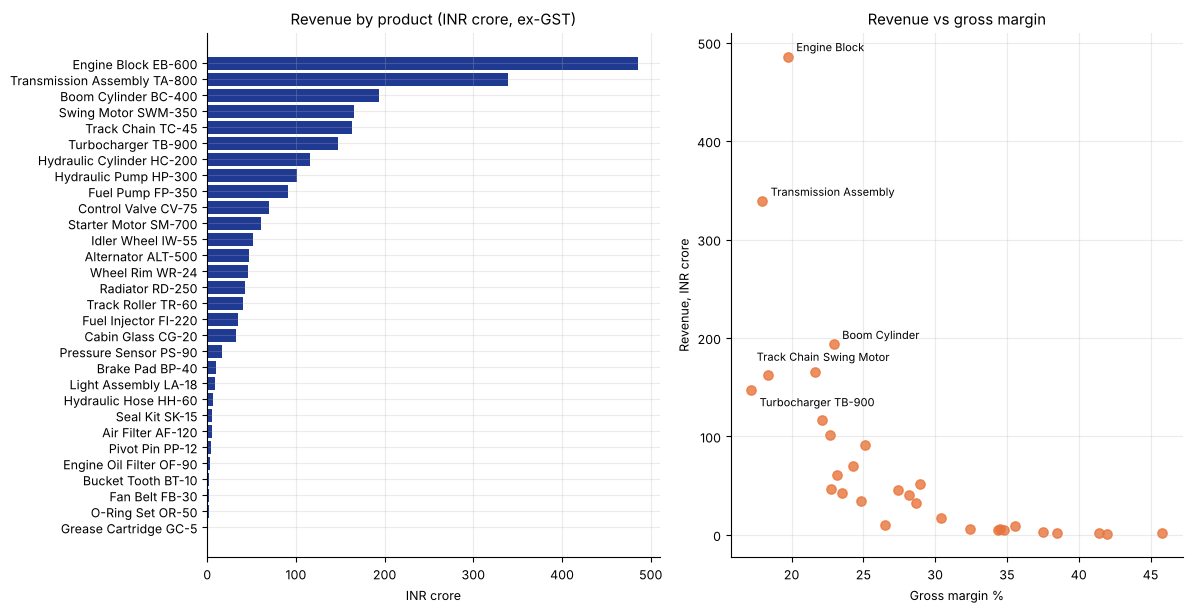

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6.2))
p = perf.sort_values("revenue")
ax[0].barh(p.product_name, p.revenue / 1e7, color=BLUE)
ax[0].set_title("Revenue by product (INR crore, ex-GST)"); ax[0].set_xlabel("INR crore")
ax[1].scatter(perf.gross_margin_pct, perf.revenue / 1e7, s=45, color=ORANGE, alpha=.8)
offs = [(6, 4), (6, 4), (6, 4), (6, 8), (-8, 10), (6, -12)]
for (_, r), o in zip(perf.head(6).iterrows(), offs):
    ax[1].annotate(" ".join(r.product_name.split(" ")[:2]), (r.gross_margin_pct, r.revenue / 1e7),
                   xytext=o, textcoords="offset points", fontsize=8)
ax[1].set_title("Revenue vs gross margin"); ax[1].set_xlabel("Gross margin %"); ax[1].set_ylabel("Revenue, INR crore")
save("01_product_performance")

In [5]:
cat = (perf.groupby("category", as_index=False)
           .agg(products=("product_id", "count"), units=("units", "sum"), revenue=("revenue", "sum"), cost=("cost", "sum")))
cat["gross_margin_pct"] = (cat.revenue - cat.cost) / cat.revenue * 100
cat["revenue_share_pct"] = cat.revenue / cat.revenue.sum() * 100
cat = cat.sort_values("revenue", ascending=False).reset_index(drop=True)
cat["revenue_cr"] = cat.revenue / 1e7
cat.round({"revenue_cr": 1, "gross_margin_pct": 1, "revenue_share_pct": 1})[
    ["category", "products", "units", "revenue_cr", "revenue_share_pct", "gross_margin_pct"]]

,category,products,units,revenue_cr,revenue_share_pct,gross_margin_pct
0,Engine,4,165182,758.6,33.0,20.1
1,Hydraulic,6,250257,652.0,28.4,22.6
2,Transmission,1,40574,338.8,14.8,18.0
3,Undercarriage,4,161405,301.6,13.1,22.9
4,Electrical,3,123682,116.6,5.1,24.0
5,Cooling,1,41770,42.6,1.9,23.5
6,Cabin,1,41091,32.3,1.4,28.7
7,Sensors,1,42702,16.9,0.7,30.4
8,Brakes,1,41549,10.2,0.4,26.5
9,Filters,2,82629,8.2,0.4,35.5


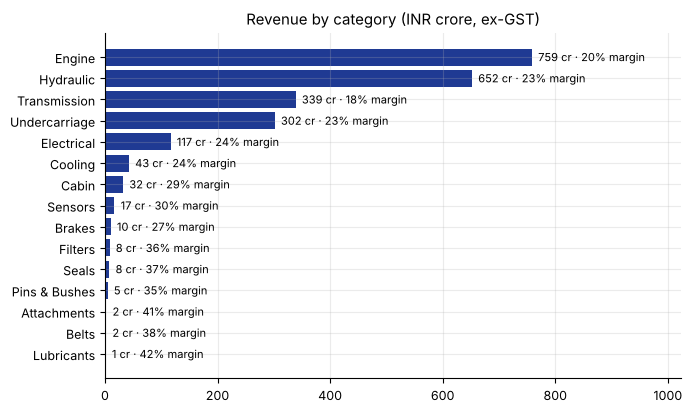

In [6]:
c = cat.sort_values("revenue")
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(c.category, c.revenue_cr, color=BLUE)
for y, (v, m) in enumerate(zip(c.revenue_cr, c.gross_margin_pct)):
    ax.text(v, y, f"  {v:,.0f} cr · {m:.0f}% margin", va="center", fontsize=8)
ax.set_title("Revenue by category (INR crore, ex-GST)"); ax.set_xlim(0, c.revenue_cr.max() * 1.35)
save("02_category_revenue")

## 3. ABC / Pareto Classification
Products are ranked by revenue. **A** = the products that make up the first 80% of cumulative revenue, **B** = the next 15% (80–95%), **C** = the last 5%.
A product's class is decided by the cumulative share *before* it is added, so the product that crosses a threshold stays in the higher class.

In [7]:
perf["cum_share_pct"] = perf.revenue_share_pct.cumsum()
before = perf.cum_share_pct - perf.revenue_share_pct
perf["abc_class"] = np.select([before < 80, before < 95], ["A", "B"], "C")

abc = perf.groupby("abc_class").agg(products=("product_id", "count"), revenue_share_pct=("revenue_share_pct", "sum"),
                                    units_share_pct=("units", lambda s: s.sum() / perf.units.sum() * 100)).round(1)
print(abc.to_string())
print("\nA-class products:", ", ".join(perf[perf.abc_class == "A"].product_name))

           products  revenue_share_pct  units_share_pct
abc_class                                              
A                10               81.5             33.5
B                 7               14.1             23.1
C                13                4.4             43.4

A-class products: Engine Block EB-600, Transmission Assembly TA-800, Boom Cylinder BC-400, Swing Motor SWM-350, Track Chain TC-45, Turbocharger TB-900, Hydraulic Cylinder HC-200, Hydraulic Pump HP-300, Fuel Pump FP-350, Control Valve CV-75

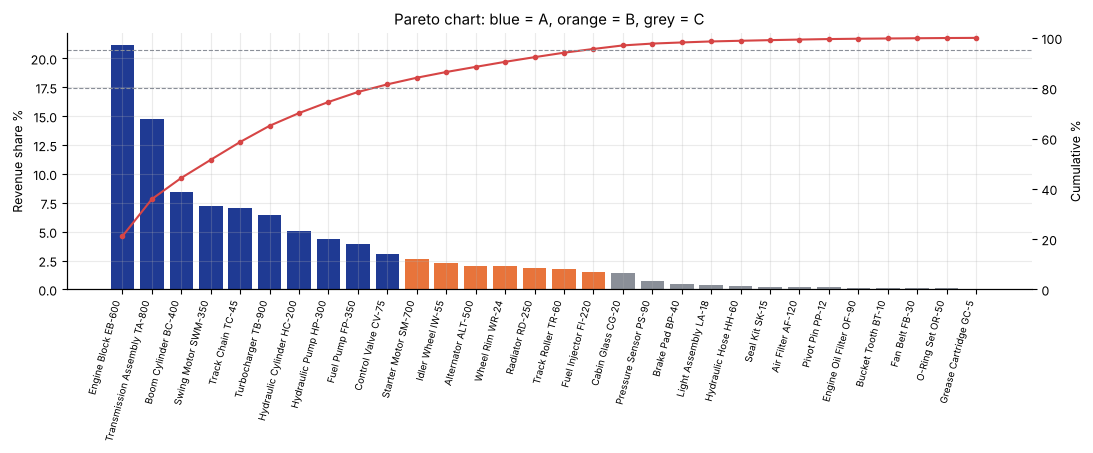

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.6))
col = perf.abc_class.map({"A": BLUE, "B": ORANGE, "C": GREY})
ax.bar(range(len(perf)), perf.revenue_share_pct, color=col)
ax.set_xticks(range(len(perf))); ax.set_xticklabels(perf.product_name, rotation=75, ha="right", fontsize=7)
ax.set_ylabel("Revenue share %")
ax2 = ax.twinx(); ax2.plot(range(len(perf)), perf.cum_share_pct, color=RED, marker="o", ms=3)
ax2.axhline(80, ls="--", c=GREY, lw=.8); ax2.axhline(95, ls="--", c=GREY, lw=.8); ax2.set_ylim(0, 102); ax2.set_ylabel("Cumulative %")
ax2.grid(False); ax.set_title("Pareto chart: blue = A, orange = B, grey = C")
save("03_pareto_abc")

## 4. Fast-Moving Product Identification
**Basis: order lines (how often a product is picked)**, ranked into thirds: top 10 = Fast, middle 10 = Medium, bottom 10 = Slow.
Order lines measure picking frequency, which is what drives warehouse handling effort, so this is the basis used for movement. Units sold is shown alongside as a cross-check.

In [9]:
perf["velocity_rank"] = perf.order_lines.rank(ascending=False, method="first").astype(int)
perf["velocity_class"] = pd.cut(perf.velocity_rank, [0, 10, 20, 30], labels=["Fast", "Medium", "Slow"]).astype(str)
perf["avg_daily_units"] = perf.units / N_DAYS
perf["units_rank"] = perf.units.rank(ascending=False, method="first").astype(int)

v = perf.groupby("velocity_class").agg(products=("product_id", "count"), order_lines=("order_lines", "sum"),
                                       units=("units", "sum"), avg_daily_units=("avg_daily_units", "sum")).loc[["Fast", "Medium", "Slow"]]
print(v.round(1).to_string())
fast, slow = v.loc["Fast"], v.loc["Slow"]
print(f"\nFast vs Slow: {fast.order_lines/slow.order_lines*100-100:.1f}% more order lines, {fast.units/slow.units*100-100:.1f}% more units")

by_units = pd.cut(perf.units_rank, [0, 10, 20, 30], labels=["Fast", "Medium", "Slow"]).astype(str)
print(f"Products given the same class by units sold as by order lines: {(by_units == perf.velocity_class).sum()} of 30")

                products  order_lines   units  avg_daily_units
velocity_class                                                
Fast                  10        39879  418580            191.0
Medium                10        39205  411769            187.9
Slow                  10        38572  404590            184.6

Fast vs Slow: 3.4% more order lines, 3.5% more units
Products given the same class by units sold as by order lines: 22 of 30

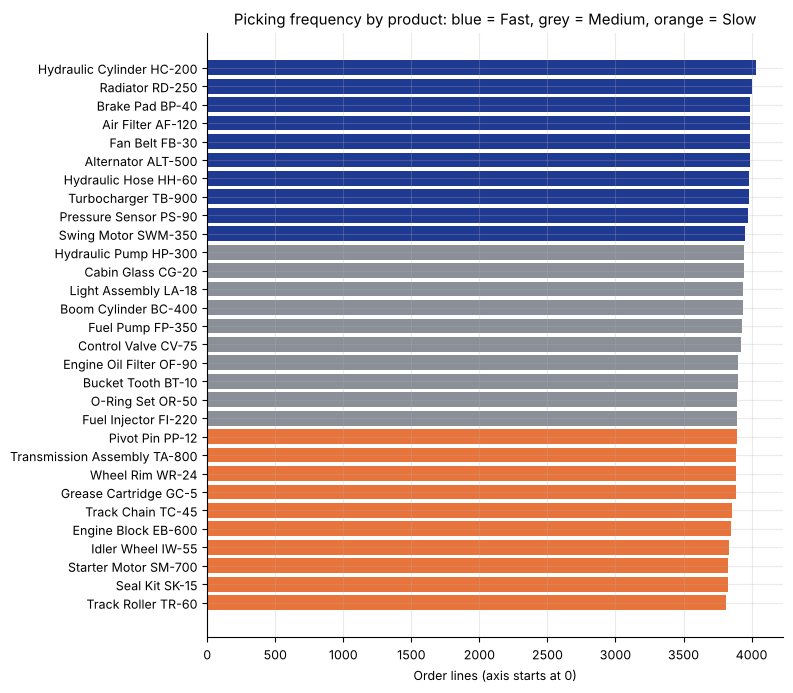

In [10]:
p = perf.sort_values("order_lines")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(p.product_name, p.order_lines, color=p.velocity_class.map({"Fast": BLUE, "Medium": GREY, "Slow": ORANGE}))
ax.set_xlabel("Order lines (axis starts at 0)"); ax.set_title("Picking frequency by product: blue = Fast, grey = Medium, orange = Slow")
save("04_velocity")

## 5. Slow-Moving & Dead Stock Identification
- **Slow-moving** = the bottom third by order lines (section 4).
- **Dead stock** = no sale in the last 90 days of the data (to 2024-12-31). The threshold is a parameter and can be changed.

In [11]:
DEAD_DAYS = 90
last_sale = d.groupby("product_id").order_date.max()
perf["days_since_last_sale"] = perf.product_id.map((END - last_sale).dt.days)
perf["units_last_90d"] = perf.product_id.map(d[d.order_date > END - pd.Timedelta(days=DEAD_DAYS)].groupby("product_id").quantity.sum())
perf["dead_stock_flag"] = perf.days_since_last_sale >= DEAD_DAYS

print(f"Dead-stock products (no sale in {DEAD_DAYS}+ days): {perf.dead_stock_flag.sum()}")
print(f"Longest gap since last sale: {perf.days_since_last_sale.max()} day(s);  fewest units sold in last {DEAD_DAYS} days: {perf.units_last_90d.min():,.0f}")
slow_list = perf[perf.velocity_class == "Slow"].sort_values("order_lines")
slow_list[["product_name", "category", "abc_class", "order_lines", "units", "days_since_last_sale", "units_last_90d"]]

Dead-stock products (no sale in 90+ days): 0
Longest gap since last sale: 1 day(s);  fewest units sold in last 90 days: 1,304

,product_name,category,abc_class,order_lines,units,days_since_last_sale,units_last_90d
15,Track Roller TR-60,Undercarriage,B,3815,39486,0,1304
22,Seal Kit SK-15,Seals,C,3828,39927,1,1678
10,Starter Motor SM-700,Electrical,B,3829,40547,0,1458
11,Idler Wheel IW-55,Undercarriage,B,3835,40276,0,1406
0,Engine Block EB-600,Engine,A,3851,40815,0,1607
4,Track Chain TC-45,Undercarriage,A,3856,40891,0,1801
29,Grease Cartridge GC-5,Lubricants,C,3888,40407,1,1637
1,Transmission Assembly TA-800,Transmission,A,3889,40574,1,1671
13,Wheel Rim WR-24,Undercarriage,B,3889,40752,0,1448
24,Pivot Pin PP-12,Pins & Bushes,C,3892,40915,0,1478


## 6. Product Demand Trend Analysis
Trend per product = slope of a straight line fitted to its 72 monthly unit totals, expressed as % of its average monthly units per year.
A product is called **Growing** or **Declining** only when the trend is beyond ±2% a year **and** statistically significant (p < 0.05); otherwise it is **Stable**. With 30 products, about 1–2 will look "significant" by chance alone, so the significant count is compared with that. Year-on-year swings are shown separately so that noise is not mistaken for trend.

In [12]:
m = d.groupby(["product_id", "month"]).quantity.sum().unstack(fill_value=0)
t = np.arange(m.shape[1]) / 12
fits = {pid: stats.linregress(t, row.values) for pid, row in m.iterrows()}
perf["trend_pct_per_year"] = perf.product_id.map({k: f.slope / m.loc[k].mean() * 100 for k, f in fits.items()})
perf["trend_p_value"] = perf.product_id.map({k: f.pvalue for k, f in fits.items()})
yearly = d.groupby(["product_id", "year"]).quantity.sum().unstack()
perf["yoy_2024_vs_2023_pct"] = perf.product_id.map((yearly[2024] / yearly[2023] - 1) * 100)
sig = perf.trend_p_value < 0.05
perf["trend_class"] = np.select([sig & (perf.trend_pct_per_year > 2), sig & (perf.trend_pct_per_year < -2)], ["Growing", "Declining"], "Stable")

print(perf.trend_class.value_counts().to_string())
print(f"\nProducts with a statistically significant trend (p<0.05): {int(sig.sum())} of 30 (about 1.5 expected by chance alone)")
print(f"Trend range: {perf.trend_pct_per_year.min():+.2f}% to {perf.trend_pct_per_year.max():+.2f}% a year")
print(f"2024 vs 2023 change by product: {perf.yoy_2024_vs_2023_pct.min():+.1f}% to {perf.yoy_2024_vs_2023_pct.max():+.1f}% (single-year swings)")
print("Network units by year:", d.groupby("year").quantity.sum().to_dict())

trend_class
Stable       29
Declining     1

Products with a statistically significant trend (p<0.05): 1 of 30 (about 1.5 expected by chance alone)
Trend range: -2.34% to +2.04% a year
2024 vs 2023 change by product: -15.6% to +13.4% (single-year swings)
Network units by year: {2019: 207925, 2020: 212007, 2021: 208269, 2022: 202242, 2023: 204638, 2024: 199858}

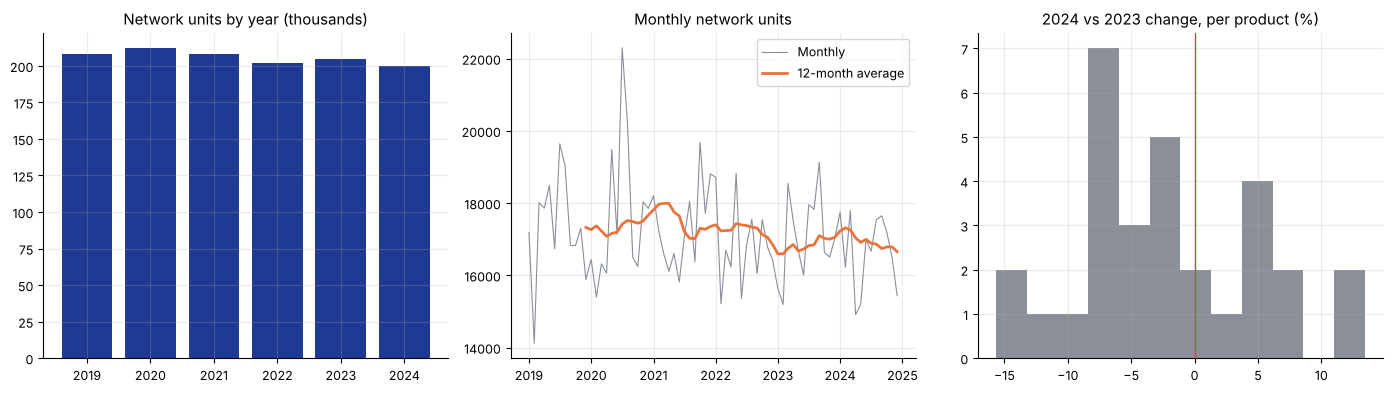

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
y = d.groupby("year").quantity.sum()
ax[0].bar(y.index.astype(str), y.values / 1e3, color=BLUE); ax[0].set_title("Network units by year (thousands)")
mm = d.groupby("month").quantity.sum(); mm.index = mm.index.to_timestamp()
ax[1].plot(mm.index, mm.values, color=GREY, lw=.8, label="Monthly"); ax[1].plot(mm.index, mm.rolling(12).mean(), color=ORANGE, lw=2, label="12-month average")
ax[1].set_title("Monthly network units"); ax[1].legend()
ax[2].hist(perf.yoy_2024_vs_2023_pct, bins=12, color=GREY); ax[2].axvline(0, c=RED, lw=1)
ax[2].set_title("2024 vs 2023 change, per product (%)")
save("05_demand_trend")

In [14]:
season = (d.assign(cal_month=d.order_date.dt.month).groupby("cal_month").quantity.sum())
season_idx = (season / season.mean() * 100).round(1)
print("Seasonality index (100 = average month):"); print(season_idx.to_string())

Seasonality index (100 = average month):
cal_month
1     101.0
2      90.7
3     101.0
4      95.9
5     102.3
6      95.3
7     107.3
8     107.1
9      99.6
10    101.2
11     99.9
12     98.6

## 7. Inventory Turnover Analysis
Turnover = units sold in the **last 12 months of delivered orders** ÷ current stock. Days of cover = stock ÷ daily sales. Using the last 12 months (not all history, not ledger OUT) matches the Week 5 basis and avoids the ledger's 9% shortfall.

In [15]:
L12 = d[d.order_date > END - pd.Timedelta(days=365)]
stock = inv.groupby("product_id").current_stock.sum()
perf["current_stock"] = perf.product_id.map(stock)
perf["units_L12M"] = perf.product_id.map(L12.groupby("product_id").quantity.sum())
perf["annual_turnover"] = perf.units_L12M / perf.current_stock
perf["days_of_cover"] = perf.current_stock / perf.units_L12M * 365
perf["years_of_supply"] = perf.days_of_cover / 365

tot_stock, tot_u = inv.current_stock.sum(), L12.quantity.sum()
print(f"Network: stock {tot_stock:,}  units sold last 12 months {tot_u:,}  turnover {tot_u/tot_stock:.4f} a year")
print(f"         days of cover {tot_stock/tot_u*365:,.0f}  =  {tot_stock/tot_u:.1f} years of supply")
print(f"Product range: {perf.years_of_supply.min():.1f} to {perf.years_of_supply.max():.1f} years of supply")
print(f"Positions flagged scale_mismatch_flag in Week 3: {int(inv.scale_mismatch_flag.sum())} of {len(inv)}")
perf.sort_values("years_of_supply")[["product_name", "abc_class", "units_L12M", "current_stock", "annual_turnover", "years_of_supply"]].round(
    {"annual_turnover": 4, "years_of_supply": 1}).head(8)

Network: stock 19,303,266  units sold last 12 months 199,029  turnover 0.0103 a year
         days of cover 35,400  =  97.0 years of supply
Product range: 85.0 to 108.2 years of supply
Positions flagged scale_mismatch_flag in Week 3: 180 of 180

,product_name,abc_class,units_L12M,current_stock,annual_turnover,years_of_supply
18,Pressure Sensor PS-90,C,7471,634978,0.0118,85.0
8,Fuel Pump FP-350,A,7126,632290,0.0113,88.7
12,Alternator ALT-500,B,7118,647154,0.0110,90.9
14,Radiator RD-250,B,6948,633960,0.0110,91.2
28,O-Ring Set OR-50,C,6883,630991,0.0109,91.7
25,Engine Oil Filter OF-90,C,7119,655012,0.0109,92.0
26,Bucket Tooth BT-10,C,6726,624694,0.0108,92.9
2,Boom Cylinder BC-400,A,6757,630617,0.0107,93.3


In [16]:
br = pd.DataFrame({"units_L12M": L12.groupby("branch_id").quantity.sum(), "current_stock": inv.groupby("branch_id").current_stock.sum()})
br["branch_name"] = br.index.map(inv.drop_duplicates("branch_id").set_index("branch_id").branch_name)
br["annual_turnover"] = br.units_L12M / br.current_stock
br["years_of_supply"] = br.current_stock / br.units_L12M
br = br.reset_index().sort_values("years_of_supply")
print(br.round({"annual_turnover": 4, "years_of_supply": 1}).to_string(index=False))

branch_id  units_L12M  current_stock         branch_name  annual_turnover  years_of_supply
   CHN001       40132        3234245   Chennai South Hub           0.0124             80.6
   KOL001       36956        3123805  Kolkata East Depot           0.0118             84.5
   AHM001       31524        3154992  Ahmedabad West Hub           0.0100            100.1
   DEL001       31797        3288670       Delhi Central           0.0097            103.4
   PUN001       30703        3256263   Pune Distribution           0.0094            106.1
   HYD001       27917        3245291 Hyderabad Logistics           0.0086            116.2

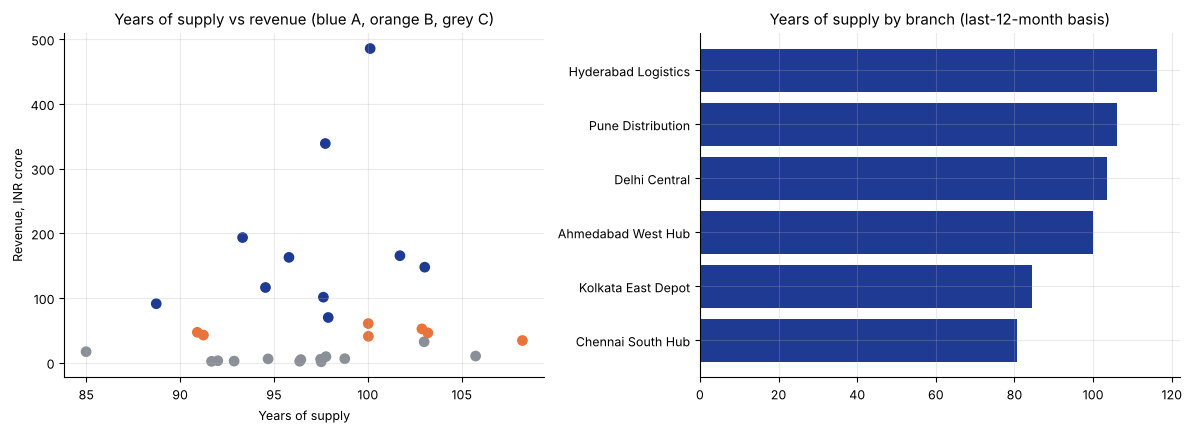

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
q = perf.sort_values("years_of_supply")
ax[0].scatter(q.years_of_supply, q.revenue / 1e7, c=q.abc_class.map({"A": BLUE, "B": ORANGE, "C": GREY}), s=45)
ax[0].set_xlabel("Years of supply"); ax[0].set_ylabel("Revenue, INR crore"); ax[0].set_title("Years of supply vs revenue (blue A, orange B, grey C)")
ax[1].barh(br.branch_name, br.years_of_supply, color=BLUE); ax[1].set_title("Years of supply by branch (last-12-month basis)")
save("06_turnover")

## 8. Export results

In [18]:
perf.to_csv(OUT_DIR / "product_performance_full.csv", index=False)
perf[["product_id", "product_name", "category", "revenue", "revenue_share_pct", "cum_share_pct", "abc_class"]].to_csv(OUT_DIR / "abc_classification.csv", index=False)
perf[["product_id", "product_name", "order_lines", "units", "avg_daily_units", "velocity_rank", "velocity_class",
      "days_since_last_sale", "units_last_90d", "dead_stock_flag"]].to_csv(OUT_DIR / "velocity_and_dead_stock.csv", index=False)
perf[["product_id", "product_name", "trend_pct_per_year", "trend_p_value", "trend_class", "yoy_2024_vs_2023_pct"]].to_csv(OUT_DIR / "demand_trend.csv", index=False)
perf[["product_id", "product_name", "units_L12M", "current_stock", "annual_turnover", "days_of_cover", "years_of_supply"]].to_csv(OUT_DIR / "turnover_by_product.csv", index=False)
br.to_csv(OUT_DIR / "turnover_by_branch.csv", index=False); cat.to_csv(OUT_DIR / "category_performance.csv", index=False)
print(sorted(p.name for p in OUT_DIR.glob("*.csv")), len(list((OUT_DIR / "charts").glob("*.png"))), "charts")

['abc_classification.csv', 'category_performance.csv', 'demand_trend.csv', 'product_performance_full.csv', 'turnover_by_branch.csv', 'turnover_by_product.csv', 'velocity_and_dead_stock.csv'] 6 charts